In [1]:
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from datetime import timedelta
import numpy as np

try:
    df = pd.read_csv('../2022-2025.csv')
except:
    df = pd.read_csv('../2022-2025.csv', sep=',', engine='python')

# Filtrar solo 'Purchase' (P) limpiando espacios en blanco
df['Tx_Type'] = df['Tx_Type'].astype(str).str.strip().str.upper()
df_strat = df[df['Tx_Type'] == 'P'].copy()

df_strat['Buy_Date'] = pd.to_datetime(df_strat['Notif_Date'], errors='coerce', dayfirst=False)

df_strat = df_strat.dropna(subset=['Buy_Date'])

df_strat = df_strat.dropna(subset=['Acronym'])
df_strat['Acronym'] = df_strat['Acronym'].str.strip().str.upper()

df_strat = df_strat[df_strat["Filing Status"] == 'new']

print(f"Operaciones a analizar: {len(df_strat)}")
df_strat[['Buy_Date', 'Acronym', 'Asset']].head()

Operaciones a analizar: 6730


,Buy_Date,Acronym,Asset
7,2022-01-03,AM,Antero Midstream Corporation (AM) [ST]
10,2022-01-03,ENLC,"Enlink Midstream, llC Common units representin..."
12,2021-11-24,NGL,NGl ENERGY PARTNERS lP Common units representi...
14,2022-01-03,PBFX,PbF logistics lP Common units representing lim...
15,2022-01-03,PAA,"Plains All American Pipeline, l.P. - Common un..."


In [2]:
import time
import pandas as pd
import yfinance as yf
import numpy as np


tickers = df_strat['Acronym'].dropna().unique().tolist()
print(f"Total de tickers únicos a descargar: {len(tickers)}")

BATCH_SIZE = 40
PAUSE_SECONDS = 1.5

def chunked_list(lst, n):
    for i in range(0, len(lst), n):
        yield lst[i:i + n]

data_frames_list = []

print(f"Iniciando descarga en tandas de {BATCH_SIZE}...")
chunks = list(chunked_list(tickers, BATCH_SIZE))

for i, batch in enumerate(chunks):
    print(f"Descargando lote {i+1}/{len(chunks)}...", end=" ")
    try:
        batch_data = yf.download(batch, start="2021-01-01", progress=False, auto_adjust=True)
        
        if len(batch) > 1:
            close_prices = batch_data['Close']
        else:
            close_prices = pd.DataFrame({batch[0]: batch_data['Close']})
            
        data_frames_list.append(close_prices)
        print("OK.")
    except Exception as e:
        print(f"Error: {e}")
    time.sleep(PAUSE_SECONDS)

print("Unificando datos...")
if data_frames_list:
    hist_data = pd.concat(data_frames_list, axis=1)
    hist_data = hist_data.dropna(axis=1, how='all')
else:
    hist_data = pd.DataFrame()

print(f"Matriz de precios final: {hist_data.shape}")


Total de tickers únicos a descargar: 1355
Iniciando descarga en tandas de 40...
Descargando lote 1/34... 

$ITCI: possibly delisted; no timezone found
$TWTR: possibly delisted; no timezone found
$ENLC: possibly delisted; no timezone found
$PBFX: possibly delisted; no timezone found
$IS: possibly delisted; no timezone found
$ANTM: possibly delisted; no timezone found

6 Failed downloads:
['ITCI', 'TWTR', 'ENLC', 'PBFX', 'IS', 'ANTM']: possibly delisted; no timezone found


OK.
Descargando lote 2/34... 

$SRLP: possibly delisted; no timezone found
$WRK: possibly delisted; no timezone found
$PXD: possibly delisted; no timezone found
$BRK: possibly delisted; no price data found  (1d 2021-01-01 -> 2026-11-07) (Yahoo error = "No data found, symbol may be delisted")
$TELL: possibly delisted; no timezone found

5 Failed downloads:
['SRLP', 'WRK', 'PXD', 'TELL']: possibly delisted; no timezone found
['BRK']: possibly delisted; no price data found  (1d 2021-01-01 -> 2026-11-07) (Yahoo error = "No data found, symbol may be delisted")


OK.
Descargando lote 3/34... 

$BF: possibly delisted; no price data found  (1d 2021-01-01 -> 2026-11-07) (Yahoo error = "No data found, symbol may be delisted")
$SQ: possibly delisted; no timezone found
$PSXP: possibly delisted; no timezone found

3 Failed downloads:
['BF']: possibly delisted; no price data found  (1d 2021-01-01 -> 2026-11-07) (Yahoo error = "No data found, symbol may be delisted")
['SQ', 'PSXP']: possibly delisted; no timezone found


... (63 outputs left out)

$BHLB: possibly delisted; no timezone found

1 Failed download:
['BHLB']: possibly delisted; no timezone found


OK.
Descargando lote 34/34... 

$ICAPITAL: possibly delisted; no timezone found
$XMEX: possibly delisted; no timezone found

2 Failed downloads:
['ICAPITAL', 'XMEX']: possibly delisted; no timezone found


OK.
Unificando datos...
Matriz de precios final: (1469, 1235)


In [3]:
#df_strat['Buy_Date'] = pd.to_datetime(df_strat['Date'], errors='coerce', dayfirst=False)

df_strat = df_strat.dropna(subset=['Buy_Date'])

#Vendemos 19 dias despues
df_strat['Sell_Date'] = df_strat['Buy_Date'] + timedelta(days=19)


def get_price_robust(ticker, target_date, lookup_df, method='exact'):
    if ticker not in lookup_df.columns: return np.nan
    series = lookup_df[ticker].dropna()
    if series.empty: return np.nan
    try:
        if method == 'forward':
            idx = series.index.get_indexer([target_date], method='bfill')[0]
        elif method == 'nearest':
            idx = series.index.get_indexer([target_date], method='nearest')[0]
        else:
            idx = -1
        if idx != -1 and idx < len(series): return series.iloc[idx]
    except: return np.nan
    return np.nan

print("Calculando precios de entrada y salida...")
df_strat['Buy_Price'] = df_strat.apply(lambda row: get_price_robust(row['Acronym'], row['Buy_Date'], hist_data, 'forward'), axis=1)
df_strat['Sell_Price'] = df_strat.apply(lambda row: get_price_robust(row['Acronym'], row['Sell_Date'], hist_data, 'nearest'), axis=1)
df_strat['Return'] = (df_strat['Sell_Price'] - df_strat['Buy_Price']) / df_strat['Buy_Price']
df_strat['Return'] = df_strat['Return'].fillna(0.0)

total_ops = len(df_strat)
ops_con_precio = len(df_strat[df_strat['Buy_Price'] > 0])
ops_fallidas = total_ops - ops_con_precio

print(f"\n--- DIAGNÓSTICO 2025 ---")
print(f"Total Operaciones: {total_ops}")
print(f"Operaciones Válidas: {ops_con_precio}")
print(f"Fallidas: {ops_fallidas}")

df_clean = df_strat[df_strat['Buy_Price'] > 0].copy()

Calculando precios de entrada y salida...

--- DIAGNÓSTICO 2025 ---
Total Operaciones: 6730
Operaciones Válidas: 6364
Fallidas: 366


Descargando datos del S&P 500 (SPY) para la comparativa...
Simulando las mismas operaciones en el S&P 500...


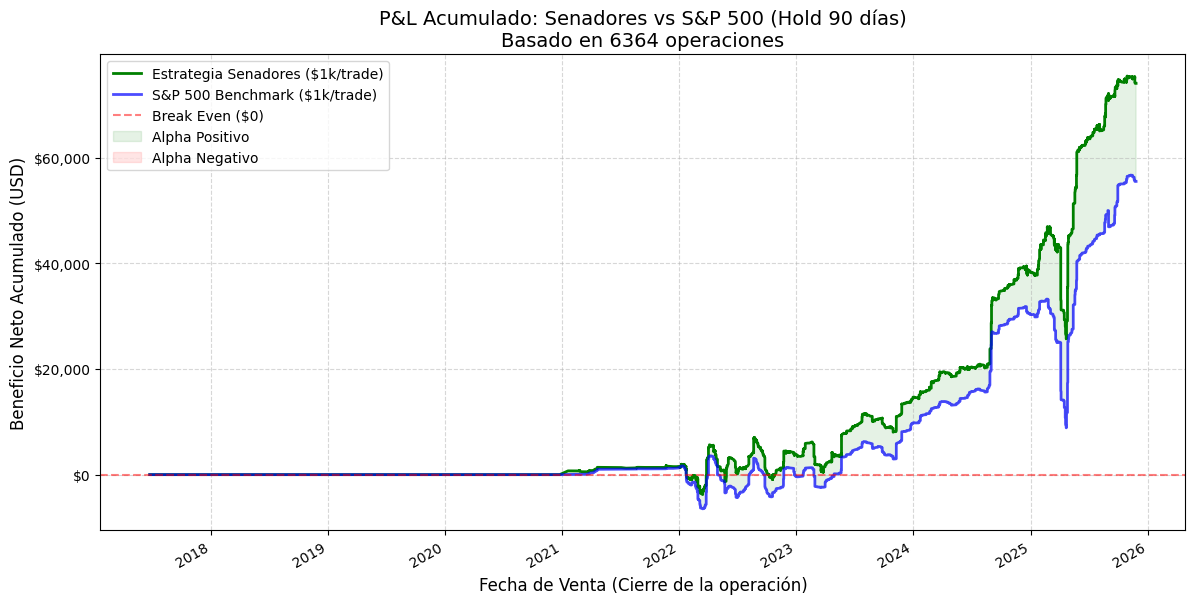


--- RESULTADOS COMPARATIVOS (Por cada $1,000 por operación) ---
Total Operaciones Cerradas: 6364
Capital total movilizado: $6,364,000.00

BENEFICIO SENADORES: $74,089.63
BENEFICIO S&P 500:   $55,524.30
-> Los senadores BATIERON al mercado por: +$18,565.34 de ganancia extra.

Tasa de Acierto Senadores: 55.50%
Tasa de Acierto S&P 500:   63.50%
Retorno Promedio Senadores: 1.16%
Retorno Promedio S&P 500:   0.87%


In [4]:
import matplotlib.ticker as mtick

if len(df_clean) > 0:
    print("Descargando datos del S&P 500 (SPY) para la comparativa...")
    
    try:
        spy_data = yf.download('SPY', start="2021-01-01", progress=False, auto_adjust=True)
        if isinstance(spy_data.columns, pd.MultiIndex):
            spy_series = spy_data['Close']['SPY'].dropna()
        else:
            spy_series = spy_data['Close'].dropna()
    except Exception as e:
        print(f"Error descargando SPY: {e}")
        spy_series = pd.Series(dtype=float)

    def get_spy_price(target_date, method='forward'):
        if spy_series.empty: return np.nan
        try:
            if method == 'forward':
                idx = spy_series.index.get_indexer([target_date], method='bfill')[0]
            else:
                idx = spy_series.index.get_indexer([target_date], method='nearest')[0]
            if idx != -1 and idx < len(spy_series):
                return spy_series.iloc[idx]
        except: return np.nan
        return np.nan

    print("Simulando las mismas operaciones en el S&P 500...")
    df_clean['Buy_Price_SPY'] = df_clean['Buy_Date'].apply(lambda x: get_spy_price(x, 'forward'))
    df_clean['Sell_Price_SPY'] = df_clean['Sell_Date'].apply(lambda x: get_spy_price(x, 'nearest'))
    
    df_clean['Return_SPY'] = (df_clean['Sell_Price_SPY'] - df_clean['Buy_Price_SPY']) / df_clean['Buy_Price_SPY']
    df_clean['Return_SPY'] = df_clean['Return_SPY'].fillna(0.0)

    df_clean = df_clean.sort_values('Sell_Date')

    INVERSION_POR_TRADE = 1000

    df_clean['PnL_USD'] = df_clean['Return'] * INVERSION_POR_TRADE
    df_clean['Beneficio_Acumulado'] = df_clean['PnL_USD'].cumsum()
    
    df_clean['PnL_SPY_USD'] = df_clean['Return_SPY'] * INVERSION_POR_TRADE
    df_clean['Beneficio_Acumulado_SPY'] = df_clean['PnL_SPY_USD'].cumsum()

    plt.figure(figsize=(14, 7))
    
    plt.plot(df_clean['Sell_Date'], df_clean['Beneficio_Acumulado'], 
             label='Estrategia Senadores ($1k/trade)', color='green', linewidth=2)
    
    plt.plot(df_clean['Sell_Date'], df_clean['Beneficio_Acumulado_SPY'], 
             label='S&P 500 Benchmark ($1k/trade)', color='blue', linewidth=2, alpha=0.7)
    
    plt.axhline(y=0, color='r', linestyle='--', alpha=0.5, label='Break Even ($0)')

    plt.fill_between(df_clean['Sell_Date'], df_clean['Beneficio_Acumulado'], df_clean['Beneficio_Acumulado_SPY'], 
                     where=(df_clean['Beneficio_Acumulado'] > df_clean['Beneficio_Acumulado_SPY']), 
                     interpolate=True, color='green', alpha=0.1, label='Alpha Positivo')
                     
    plt.fill_between(df_clean['Sell_Date'], df_clean['Beneficio_Acumulado'], df_clean['Beneficio_Acumulado_SPY'], 
                     where=(df_clean['Beneficio_Acumulado'] <= df_clean['Beneficio_Acumulado_SPY']), 
                     interpolate=True, color='red', alpha=0.1, label='Alpha Negativo')

    plt.title(f'P&L Acumulado: Senadores vs S&P 500 (Hold 90 días)\nBasado en {len(df_clean)} operaciones', fontsize=14)
    plt.xlabel('Fecha de Venta (Cierre de la operación)', fontsize=12)
    plt.ylabel('Beneficio Neto Acumulado (USD)', fontsize=12)
    
    fmt = '${x:,.0f}'
    tick = mtick.StrMethodFormatter(fmt)
    plt.gca().yaxis.set_major_formatter(tick)
    
    plt.grid(True, which='both', linestyle='--', alpha=0.5)
    plt.legend()
    plt.gcf().autofmt_xdate()
    plt.show()

    print("\n--- RESULTADOS COMPARATIVOS (Por cada $1,000 por operación) ---")
    ganancia_senadores = df_clean['Beneficio_Acumulado'].iloc[-1]
    ganancia_spy = df_clean['Beneficio_Acumulado_SPY'].iloc[-1]
    alpha = ganancia_senadores - ganancia_spy
    
    capital_necesario = len(df_clean) * INVERSION_POR_TRADE
    win_rate_senadores = len(df_clean[df_clean['Return'] > 0]) / len(df_clean) * 100
    win_rate_spy = len(df_clean[df_clean['Return_SPY'] > 0]) / len(df_clean) * 100
    
    print(f"Total Operaciones Cerradas: {len(df_clean)}")
    print(f"Capital total movilizado: ${capital_necesario:,.2f}\n")
    
    print(f"BENEFICIO SENADORES: ${ganancia_senadores:,.2f}")
    print(f"BENEFICIO S&P 500:   ${ganancia_spy:,.2f}")
    
    if alpha > 0:
        print(f"-> Los senadores BATIERON al mercado por: +${alpha:,.2f} de ganancia extra.")
    else:
        print(f"-> Los senadores PERDIERON frente al mercado por: -${abs(alpha):,.2f}.")
        
    print(f"\nTasa de Acierto Senadores: {win_rate_senadores:.2f}%")
    print(f"Tasa de Acierto S&P 500:   {win_rate_spy:.2f}%")
    print(f"Retorno Promedio Senadores: {(df_clean['Return'].mean() * 100):.2f}%")
    print(f"Retorno Promedio S&P 500:   {(df_clean['Return_SPY'].mean() * 100):.2f}%")

else:
    print("No hay suficientes datos válidos para graficar.")

<>:43: SyntaxWarning: invalid escape sequence '\m'
<>:43: SyntaxWarning: invalid escape sequence '\m'
C:\Users\victo\AppData\Local\Temp\ipykernel_51264\4035923099.py:43: SyntaxWarning: invalid escape sequence '\m'
  Line2D([0], [0], marker='$\mathregular{n=X}$', color='w', label='Total de Operaciones', markerfacecolor='black', markersize=10)


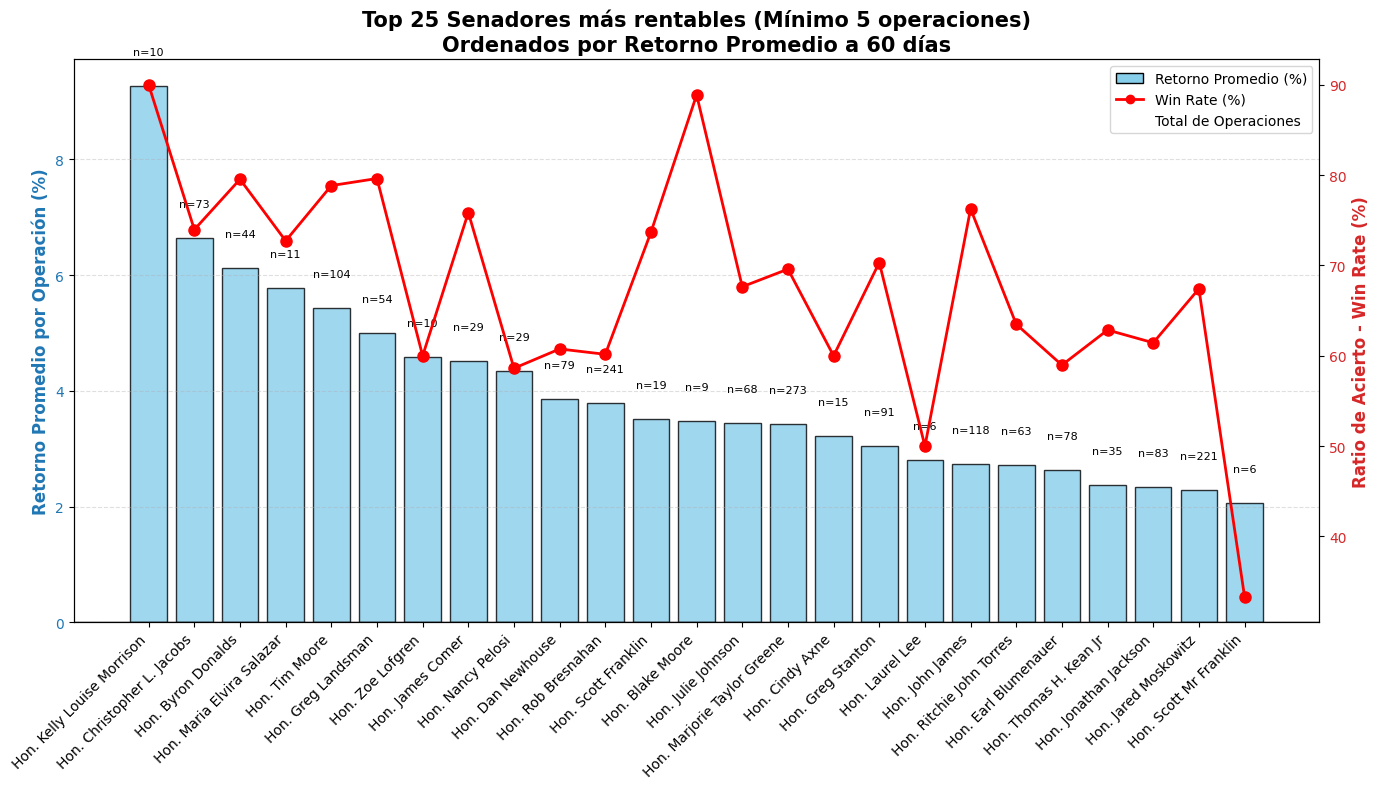


--- TOP 10 SENADORES MÁS RENTABLES ---
                      Name  Total_Operaciones  Win_Rate  Retorno_Promedio
Hon. Kelly Louise Morrison                 10 90.000000          9.265010
Hon. Christopher L. Jacobs                 73 73.972603          6.647725
        Hon. Byron Donalds                 44 79.545455          6.114162
 Hon. Maria Elvira Salazar                 11 72.727273          5.780977
            Hon. Tim Moore                104 78.846154          5.422975
        Hon. Greg Landsman                 54 79.629630          5.003151
          Hon. Zoe Lofgren                 10 60.000000          4.591084
          Hon. James Comer                 29 75.862069          4.521066
         Hon. Nancy Pelosi                 29 58.620690          4.334769
         Hon. Dan Newhouse                 79 60.759494          3.859747

--- LOS 5 SENADORES MENOS RENTABLES (Que más pierden) ---
                  Name  Total_Operaciones  Win_Rate  Retorno_Promedio
       Hon. Max M

In [5]:
ranking = df_clean.groupby('Name').agg(
    Total_Operaciones=('Return', 'count'),
    Win_Rate=('Return', lambda x: (x > 0).mean() * 100),
    Retorno_Promedio=('Return', lambda x: x.mean() * 100)
).reset_index()

MIN_OPERACIONES = 5
ranking = ranking[ranking['Total_Operaciones'] >= MIN_OPERACIONES]

ranking = ranking.sort_values('Retorno_Promedio', ascending=False)

TOP_N = 25
ranking_top = ranking.head(TOP_N)

fig, ax1 = plt.subplots(figsize=(14, 8))

bars = ax1.bar(ranking_top['Name'], ranking_top['Retorno_Promedio'], color='skyblue', edgecolor='black', alpha=0.8)
ax1.set_ylabel('Retorno Promedio por Operación (%)', color='tab:blue', fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.set_xticks(range(len(ranking_top['Name'])))
ax1.set_xticklabels(ranking_top['Name'], rotation=45, ha='right', fontsize=10)
ax1.grid(axis='y', linestyle='--', alpha=0.4)

for bar, total in zip(bars, ranking_top['Total_Operaciones']):
    yval = bar.get_height()
    offset = 0.5 if yval >= 0 else -1.5
    ax1.text(bar.get_x() + bar.get_width()/2, yval + offset, f'n={total}', ha='center', va='bottom', fontsize=8, color='black')

ax2 = ax1.twinx()
line = ax2.plot(ranking_top['Name'], ranking_top['Win_Rate'], color='red', marker='o', linestyle='-', linewidth=2, markersize=8)
ax2.set_ylabel('Ratio de Acierto - Win Rate (%)', color='tab:red', fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor='tab:red')

ax1.axhline(0, color='black', linewidth=1)

plt.title(f'Top {len(ranking_top)} Senadores más rentables (Mínimo {MIN_OPERACIONES} operaciones)\nOrdenados por Retorno Promedio a 60 días', fontsize=15, fontweight='bold')

from matplotlib.patches import Patch
from matplotlib.lines import Line2D
legend_elements = [
    Patch(facecolor='skyblue', edgecolor='black', label='Retorno Promedio (%)'),
    Line2D([0], [0], color='red', marker='o', lw=2, label='Win Rate (%)'),
    Line2D([0], [0], marker='$\mathregular{n=X}$', color='w', label='Total de Operaciones', markerfacecolor='black', markersize=10)
]
ax1.legend(handles=legend_elements, loc='upper right')

plt.tight_layout()
plt.show()

print("\n--- TOP 10 SENADORES MÁS RENTABLES ---")
print(ranking.head(10).to_string(index=False))

print("\n--- LOS 5 SENADORES MENOS RENTABLES (Que más pierden) ---")
print(ranking.tail(5).sort_values('Retorno_Promedio', ascending=True).to_string(index=False))

--- Top Perfiles por Volumen Transaccional (N >= 5) ---
                           Name  Total_Operaciones Win_Rate Retorno_Promedio
           Hon. Josh Gottheimer                740   54.19%            0.73%
              Hon. Lisa McClain                538   50.19%            0.15%
             Hon. Kathy Manning                378   58.20%            0.87%
            Hon. Daniel Goldman                320   51.88%            1.06%
    Hon. Marjorie Taylor Greene                273   69.60%            3.42%
             Hon. Virginia Foxx                251   52.99%            0.15%
             Hon. Rob Bresnahan                241   60.17%            3.78%
           Hon. Jared Moskowitz                221   67.42%            2.29%
                Hon. Kevin Hern                207   60.39%            0.89%
             Hon. Valerie Hoyle                189   48.68%            0.20%
          Hon. Gilbert Cisneros                186   53.23%            1.12%
          Hon. Jeffe

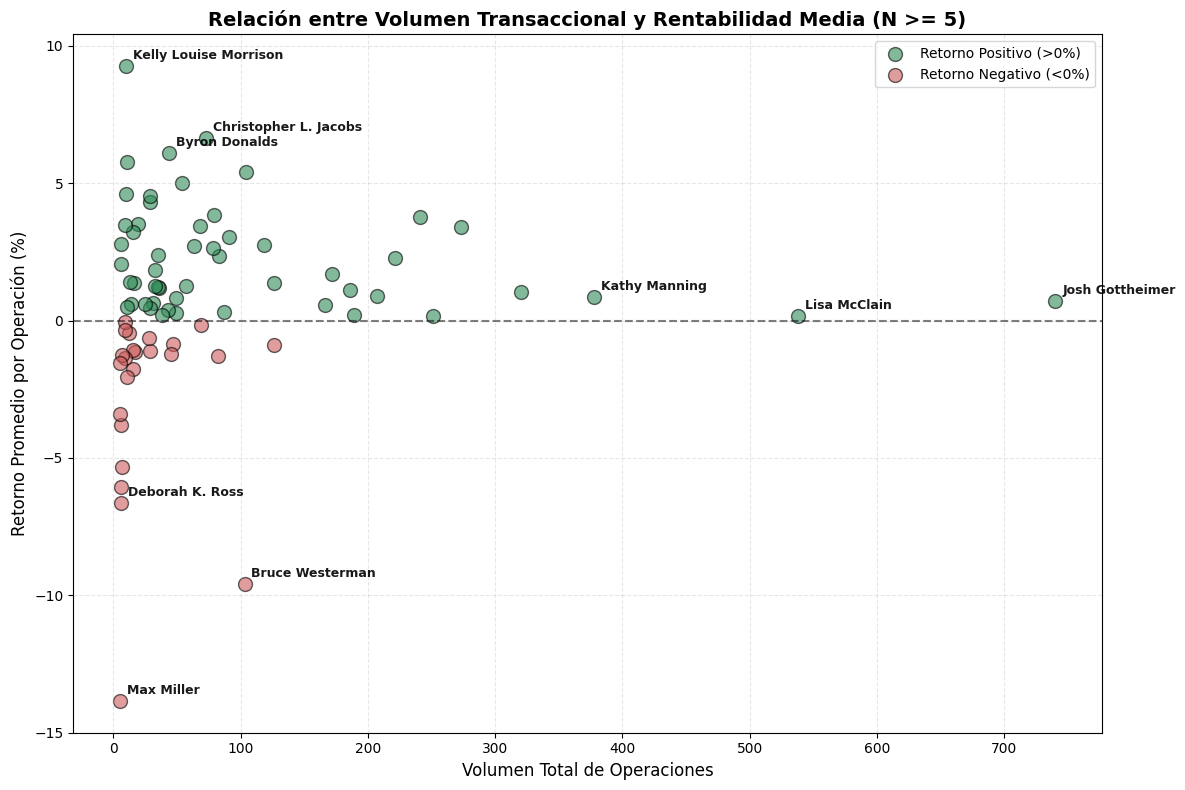

In [6]:
# Análisis de rendimiento según volumen transaccional
import pandas as pd
import matplotlib.pyplot as plt

MIN_OPERACIONES = 5

metricas_rendimiento = df_clean.groupby('Name').agg(
    Total_Operaciones=('Return', 'count'),
    Win_Rate=('Return', lambda x: (x > 0).mean() * 100),
    Retorno_Promedio=('Return', lambda x: x.mean() * 100)
).reset_index()

metricas_rendimiento = metricas_rendimiento[metricas_rendimiento['Total_Operaciones'] >= MIN_OPERACIONES]
metricas_rendimiento = metricas_rendimiento.sort_values('Total_Operaciones', ascending=False)

print(f"--- Top Perfiles por Volumen Transaccional (N >= {MIN_OPERACIONES}) ---")
tabla_formateada = metricas_rendimiento.head(20).copy()
tabla_formateada['Win_Rate'] = tabla_formateada['Win_Rate'].apply(lambda x: f"{x:.2f}%")
tabla_formateada['Retorno_Promedio'] = tabla_formateada['Retorno_Promedio'].apply(lambda x: f"{x:.2f}%")
print(tabla_formateada.to_string(index=False))

# Visualización: Relación entre Volumen y Rentabilidad Media
plt.figure(figsize=(12, 8))

ganadores = metricas_rendimiento[metricas_rendimiento['Retorno_Promedio'] >= 0]
perdedores = metricas_rendimiento[metricas_rendimiento['Retorno_Promedio'] < 0]

plt.scatter(ganadores['Total_Operaciones'], ganadores['Retorno_Promedio'], 
            color='seagreen', alpha=0.6, s=100, edgecolor='black', label='Retorno Positivo (>0%)')
plt.scatter(perdedores['Total_Operaciones'], perdedores['Retorno_Promedio'], 
            color='indianred', alpha=0.6, s=100, edgecolor='black', label='Retorno Negativo (<0%)')

plt.axhline(0, color='black', linestyle='--', alpha=0.5)

# Etiquetado de perfiles atípicos (outliers) en volumen y rentabilidad
extremos = pd.concat([
    metricas_rendimiento.nlargest(3, 'Total_Operaciones'), 
    metricas_rendimiento.nlargest(3, 'Retorno_Promedio'),
    metricas_rendimiento.nsmallest(3, 'Retorno_Promedio')
]).drop_duplicates()

for _, row in extremos.iterrows():
    # Limpieza de prefijos honoríficos para optimizar el espacio visual en el gráfico
    nombre_limpio = row['Name'].replace('Hon. ', '').replace('Mr. ', '')
    plt.annotate(
        nombre_limpio, 
        (row['Total_Operaciones'], row['Retorno_Promedio']),
        xytext=(5, 5), textcoords='offset points', fontsize=9, alpha=0.9, weight='bold'
    )

plt.title(f'Relación entre Volumen Transaccional y Rentabilidad Media (N >= {MIN_OPERACIONES})', fontsize=14, fontweight='bold')
plt.xlabel('Volumen Total de Operaciones', fontsize=12)
plt.ylabel('Retorno Promedio por Operación (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

Calculando matriz de PnL para periodos de retención variables...
Simulación completada. Generando superficies topológicas...


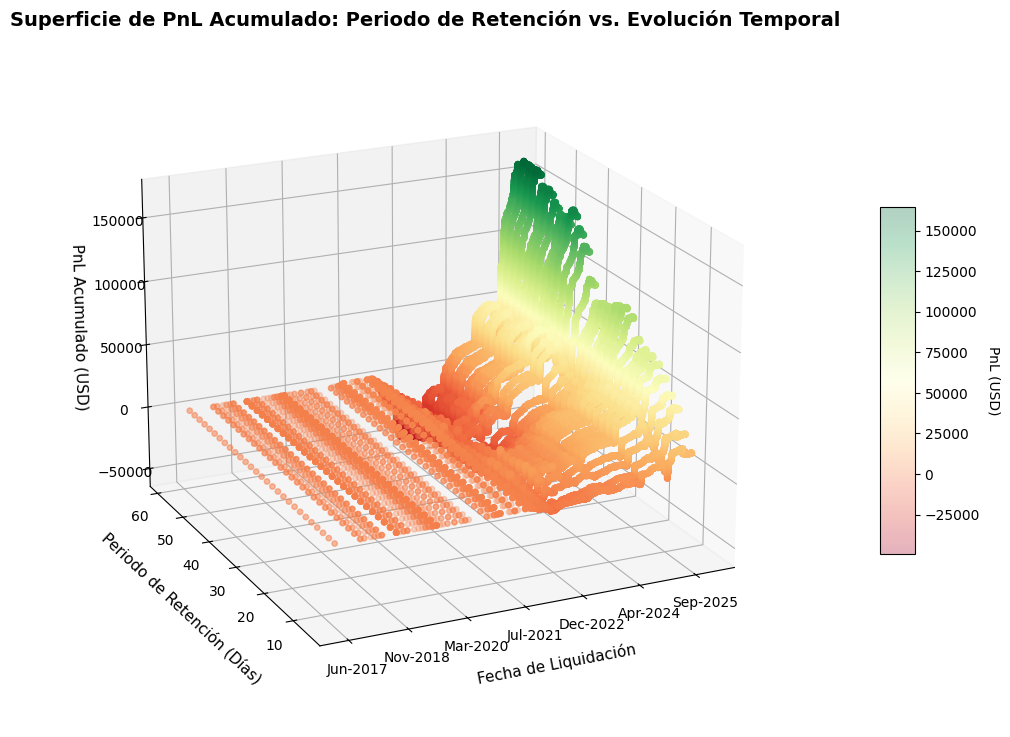

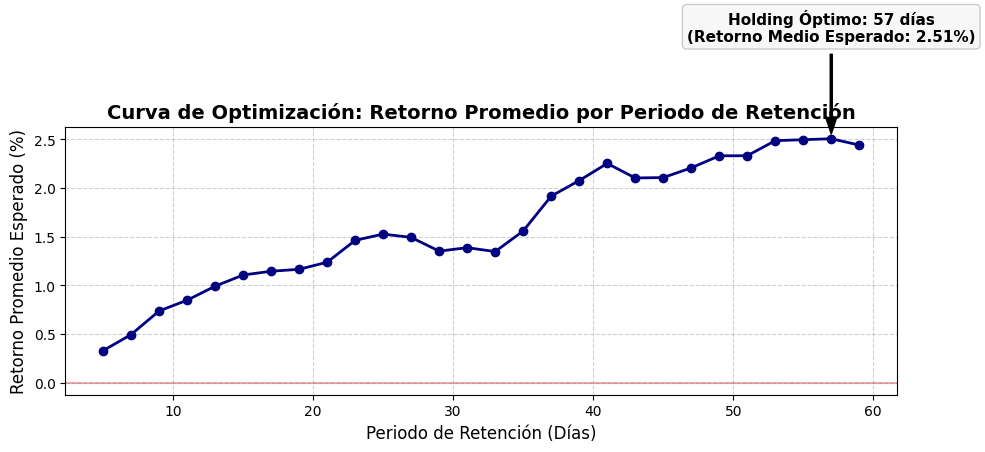

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from datetime import timedelta, date
from matplotlib.ticker import FuncFormatter

# Parámetros de simulación paramétrica
MIN_DIAS = 5
MAX_DIAS = 60
STEP_DIAS = 2
CAPITAL_POR_OPERACION = 1000.0

periodos_retencion = list(range(MIN_DIAS, MAX_DIAS, STEP_DIAS))
resultados_3d_list = []
retornos_medios = []

print("Calculando matriz de PnL para periodos de retención variables...")

for dias in periodos_retencion:
    df_sim = df_clean[['Buy_Date', 'Buy_Price', 'Acronym']].copy()
    
    df_sim['Sell_Date'] = df_sim['Buy_Date'] + timedelta(days=dias)
    
    df_sim['Sell_Price'] = df_sim.apply(
        lambda row: get_price_robust(row['Acronym'], row['Sell_Date'], hist_data, 'nearest'), axis=1
    )
    
    df_sim['Return'] = (df_sim['Sell_Price'] - df_sim['Buy_Price']) / df_sim['Buy_Price']
    df_sim['Return'] = df_sim['Return'].fillna(0.0)
    
    retornos_medios.append(df_sim['Return'].mean() * 100)
    
    df_sim = df_sim.sort_values('Sell_Date')
    df_sim['PnL_USD'] = df_sim['Return'] * CAPITAL_POR_OPERACION
    df_sim['Beneficio_Acumulado'] = df_sim['PnL_USD'].cumsum()
    
    # Vectorización de coordenadas espaciales (evitando iterrows)
    df_sim_3d = pd.DataFrame({
        'Fecha_Num': df_sim['Sell_Date'].apply(lambda x: x.toordinal()),
        'Dias_Hold': dias,
        'Beneficio': df_sim['Beneficio_Acumulado']
    })
    resultados_3d_list.append(df_sim_3d)

# Consolidación eficiente del dataset tridimensional
df_3d = pd.concat(resultados_3d_list, ignore_index=True)
print("Simulación completada. Generando superficies topológicas...")

# ==============================================================================
# VISUALIZACIÓN 1: SUPERFICIE 3D (EVOLUCIÓN TEMPORAL VS HOLDING VS PNL)
# ==============================================================================
fig = plt.figure(figsize=(14, 9))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(df_3d['Fecha_Num'], df_3d['Dias_Hold'], df_3d['Beneficio'], 
                     c=df_3d['Beneficio'], cmap='RdYlGn', alpha=0.3, s=15)

def format_date(x, pos=None):
    try:
        return date.fromordinal(int(x)).strftime('%b-%Y')
    except Exception:
        return ""

ax.xaxis.set_major_formatter(FuncFormatter(format_date))

ax.set_title('Superficie de PnL Acumulado: Periodo de Retención vs. Evolución Temporal', fontsize=14, fontweight='bold')
ax.set_xlabel('Fecha de Liquidación', fontsize=11, labelpad=10)
ax.set_ylabel('Periodo de Retención (Días)', fontsize=11, labelpad=10)
ax.set_zlabel('PnL Acumulado (USD)', fontsize=11, labelpad=10)

cbar = fig.colorbar(scatter, ax=ax, shrink=0.5, aspect=10, pad=0.1)
cbar.set_label('PnL (USD)', rotation=270, labelpad=15)

ax.view_init(elev=20, azim=-115)
plt.show()

# ==============================================================================
# VISUALIZACIÓN 2: CURVA DE OPTIMIZACIÓN DE PERIODO DE RETENCIÓN
# ==============================================================================
plt.figure(figsize=(10, 5))
plt.plot(periodos_retencion, retornos_medios, marker='o', color='navy', linewidth=2, markersize=6)

plt.title('Curva de Optimización: Retorno Promedio por Periodo de Retención', fontsize=14, fontweight='bold')
plt.xlabel('Periodo de Retención (Días)', fontsize=12)
plt.ylabel('Retorno Promedio Esperado (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

max_idx = np.argmax(retornos_medios)
holding_optimo = periodos_retencion[max_idx]
retorno_optimo = retornos_medios[max_idx]

plt.annotate(f'Holding Óptimo: {holding_optimo} días\n(Retorno Medio Esperado: {retorno_optimo:.2f}%)', 
             xy=(holding_optimo, retorno_optimo), 
             xytext=(holding_optimo, retorno_optimo + max(1.0, retorno_optimo * 0.1)),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
             fontsize=11, fontweight='bold', ha='center', 
             bbox=dict(boxstyle="round,pad=0.3", fc="whitesmoke", alpha=0.8, edgecolor='silver'))

plt.axhline(0, color='indianred', linestyle='-', alpha=0.5)
plt.tight_layout()
plt.show()

Evaluando periodos de retención y cálculo de Alpha frente al Benchmark...
Simulación completada. Generando curva de optimización...


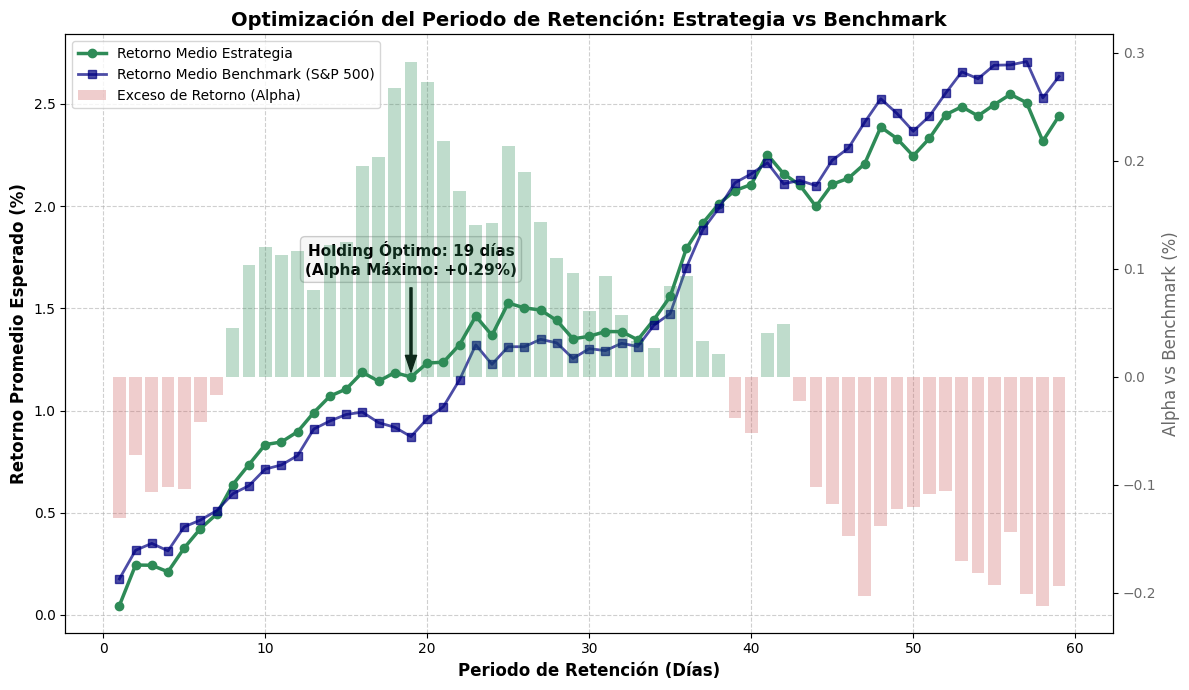

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import timedelta

# Parámetros de simulación paramétrica
MIN_DIAS_HOLD = 1
MAX_DIAS_HOLD = 60
STEP_DIAS_HOLD = 1

periodos_retencion = list(range(MIN_DIAS_HOLD, MAX_DIAS_HOLD, STEP_DIAS_HOLD))
resultados_optimizacion = []

print("Evaluando periodos de retención y cálculo de Alpha frente al Benchmark...")

for dias in periodos_retencion:
    df_sim = df_clean[['Buy_Date', 'Buy_Price', 'Acronym']].copy()
    df_sim['Sell_Date'] = df_sim['Buy_Date'] + timedelta(days=dias)
    
    # Valoración de la estrategia cuantitativa
    df_sim['Sell_Price'] = df_sim.apply(
        lambda row: get_price_robust(row['Acronym'], row['Sell_Date'], hist_data, 'nearest'), axis=1
    )
    df_sim['Return'] = (df_sim['Sell_Price'] - df_sim['Buy_Price']) / df_sim['Buy_Price']
    df_sim['Return'] = df_sim['Return'].fillna(0.0)
    
    # Valoración del Benchmark (S&P 500)
    df_sim['Buy_Price_SPY'] = df_sim['Buy_Date'].apply(lambda x: get_spy_price(x, 'forward'))
    df_sim['Sell_Price_SPY'] = df_sim['Sell_Date'].apply(lambda x: get_spy_price(x, 'nearest'))
    df_sim['Return_SPY'] = (df_sim['Sell_Price_SPY'] - df_sim['Buy_Price_SPY']) / df_sim['Buy_Price_SPY']
    df_sim['Return_SPY'] = df_sim['Return_SPY'].fillna(0.0)
    
    # Consolidación de métricas agregadas
    ret_estrategia = df_sim['Return'].mean() * 100
    ret_benchmark = df_sim['Return_SPY'].mean() * 100
    alpha = ret_estrategia - ret_benchmark
    
    resultados_optimizacion.append({
        'Dias_Hold': dias,
        'Retorno_Estrategia': ret_estrategia,
        'Retorno_Benchmark': ret_benchmark,
        'Alpha': alpha
    })

df_resultados = pd.DataFrame(resultados_optimizacion)
print("Simulación completada. Generando curva de optimización...")

# Visualización: Curva de Optimización y Alpha Acumulado
fig, ax1 = plt.subplots(figsize=(12, 7))

ax1.plot(df_resultados['Dias_Hold'], df_resultados['Retorno_Estrategia'], 
         marker='o', color='seagreen', linewidth=2.5, label='Retorno Medio Estrategia')
ax1.plot(df_resultados['Dias_Hold'], df_resultados['Retorno_Benchmark'], 
         marker='s', color='navy', linewidth=2, label='Retorno Medio Benchmark (S&P 500)', alpha=0.7)

ax1.set_xlabel('Periodo de Retención (Días)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Retorno Promedio Esperado (%)', fontsize=12, color='black', fontweight='bold')
ax1.tick_params(axis='y', labelcolor='black')
ax1.grid(True, linestyle='--', alpha=0.6)

# Eje secundario para la exposición del Alpha
ax2 = ax1.twinx()
colores_alpha = ['seagreen' if a > 0 else 'indianred' for a in df_resultados['Alpha']]

# Ajuste dinámico del ancho de barra para evitar solapamiento visual
ancho_barra = 0.8 if STEP_DIAS_HOLD == 1 else STEP_DIAS_HOLD * 0.8
ax2.bar(df_resultados['Dias_Hold'], df_resultados['Alpha'], 
        color=colores_alpha, alpha=0.3, width=ancho_barra, label='Exceso de Retorno (Alpha)')

ax2.set_ylabel('Alpha vs Benchmark (%)', fontsize=12, color='dimgray')
ax2.tick_params(axis='y', labelcolor='dimgray')

# Identificación automática del punto de Alpha máximo
max_alpha_idx = df_resultados['Alpha'].idxmax()
mejor_dia = df_resultados.loc[max_alpha_idx, 'Dias_Hold']
mejor_alpha = df_resultados.loc[max_alpha_idx, 'Alpha']
ret_optimo = df_resultados.loc[max_alpha_idx, 'Retorno_Estrategia']

ax1.annotate(f'Holding Óptimo: {mejor_dia} días\n(Alpha Máximo: +{mejor_alpha:.2f}%)', 
             xy=(mejor_dia, ret_optimo), 
             xytext=(mejor_dia, ret_optimo + max(0.5, ret_optimo * 0.15)),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
             fontsize=11, fontweight='bold', ha='center', 
             bbox=dict(boxstyle="round,pad=0.3", fc="whitesmoke", alpha=0.8, edgecolor='silver'))

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

plt.title('Optimización del Periodo de Retención: Estrategia vs Benchmark', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()